# StereoQueerEval — SEMUA eksperimen E0–E6 (otomatis)

**Tujuan**: menguji faktor penyebab Macro F1 sekitar 0,50 untuk `no`, `yes_implicit`, `yes_explicit`, mulai dari baseline lama sampai preprocessing, bobot kelas, konteks video, dan hyperparameter.

**Protokol yang benar**: belajar dari **train**, memilih konfigurasi dan checkpoint dari **validation**, membuka **test internal hanya setelah semua keputusan final**. Tidak memakai `stereotype` atau `target` sebagai input karena merupakan anotasi target lain. Setiap eksperimen dimulai dari bobot model **pretrained baru** dengan seed yang sama.

**Default**: jalankan **tujuh eksperimen E0–E6 sekaligus** untuk Twitter-XLM-RoBERTa / English sesuai eksperimen yang Anda tunjukkan. Anda dapat memilih tiga model dan tiga bahasa pada sel konfigurasi. Untuk setiap kombinasi, tujuh eksperimen dijalankan berurutan. Membutuhkan **GPU Colab** dan akses internet untuk mengambil pretrained model.

Notebook ini belum berisi hasil baru. Angka baru hanya muncul setelah **training dijalankan** di Colab. Hasil E0 dan E1 dari chat sebelumnya adalah **hasil run lama** dan tidak otomatis disalin sebagai hasil run baru.

In [ ]:
# Jalankan sekali di Google Colab lalu lanjutkan ke sel berikutnya.
%pip -q install "transformers==4.57.1" "datasets>=3,<5" "accelerate>=1,<2" "emoji>=2,<3" "sentencepiece>=0.2,<0.3" "safetensors>=0.4" "scikit-learn>=1.4" pandas matplotlib

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.0/44.0 kB 2.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 52.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 610.9/610.9 kB 20.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.4/566.4 kB 28.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.3/3.3 MB 62.9 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
diffusers 0.41.0 requires huggingface-hub<2.0,>=1.32.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio 6.30.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio-client 2.7.2 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.


## 1. Konfigurasi

`RUN_NAMES` secara default mencakup **semua E0–E6**. Agar menjalankan semua 3 model dan 3 bahasa, ganti `LANGUAGES` dan `MODEL_NAMES` sesuai contoh komentar. Jika menggunakan Google Drive, aktifkan `USE_DRIVE=True` agar hasil tidak hilang ketika runtime Colab terputus.

In [ ]:
import os, sys, re, gc, json, hashlib, shutil, unicodedata
from pathlib import Path
from itertools import combinations
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import emoji
from IPython.display import display, FileLink
from datasets import Dataset
from sklearn.metrics import (accuracy_score, f1_score, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay)
from transformers import (AutoTokenizer, AutoModelForSequenceClassification, DataCollatorWithPadding,
                          EarlyStoppingCallback, Trainer, TrainingArguments, set_seed)

os.environ["TOKENIZERS_PARALLELISM"] = "false"

# PILIHAN UTAMA: tujuh eksperimen pada Twitter-XLM-RoBERTa bahasa EN.
LANGUAGES = ["en"]
MODEL_NAMES = ["cardiffnlp/twitter-xlm-roberta-base"]
# Semua bahasa: LANGUAGES = ["en", "it", "nl"]
# Semua model: MODEL_NAMES = ["cardiffnlp/twitter-xlm-roberta-base", "FacebookAI/xlm-roberta-base",
#                             "google-bert/bert-base-multilingual-uncased"]

RUN_NAMES = ["E0_legacy", "E1_keep_emoji", "E2_keep_case", "E3_no_weights",
             "E4_title_pair", "E5_title_desc_pair", "E6_lr_warmup"]
SEED = 42
MAX_LENGTH = 384                   # Sama dengan notebook lama
NUM_EPOCHS = 10
PATIENCE = 3
TRAIN_BATCH_SIZE = 16
EVAL_BATCH_SIZE = 16
WEIGHT_DECAY = 0.01
USE_DRIVE = False                  # True: mount Drive untuk menyimpan hasil permanen
SKIP_FINISHED = True              # Aman melanjutkan setelah runtime terputus
KEEP_ONLY_WINNER_CHECKPOINT = True
RUN_FINAL_TEST = False            # SANGAT PENTING: biarkan False selama tuning E0–E6

DATA_DIR = Path("/content/data") if Path("/content").exists() else Path.cwd()
if USE_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    OUT_DIR = Path("/content/drive/MyDrive/StereoQueerEval_E0_E6")
else:
    OUT_DIR = Path("/content/ablation_results") if Path("/content").exists() else Path.cwd() / "ablation_results"
OUT_DIR.mkdir(parents=True, exist_ok=True)

LABELS = ["no", "yes_implicit", "yes_explicit"]
LABEL2ID = {label: idx for idx, label in enumerate(LABELS)}
ID2LABEL = {idx: label for label, idx in LABEL2ID.items()}
assert set(LANGUAGES).issubset({"en", "it", "nl"}) and LANGUAGES
assert MODEL_NAMES
print("Eksperimen:", RUN_NAMES)
print("Bahasa:", LANGUAGES)
print("Model:", MODEL_NAMES)
print("Total pelatihan:", len(LANGUAGES)*len(MODEL_NAMES)*len(RUN_NAMES))
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "TIDAK TERDETEKSI")
print("Folder hasil:", OUT_DIR)

Eksperimen: ['E0_legacy', 'E1_keep_emoji', 'E2_keep_case', 'E3_no_weights', 'E4_title_pair', 'E5_title_desc_pair', 'E6_lr_warmup']
Bahasa: ['en']
Model: ['cardiffnlp/twitter-xlm-roberta-base']
Total pelatihan: 7
GPU: Tesla T4
Folder hasil: /content/ablation_results


## 2. Data — CSV atau ZIP

**Opsi A:** unggah file `en-train.csv`, `en-val.csv`, `en-test.csv` ke folder `/content/data`. Untuk IT/NL, unggah pula nama yang sesuai.

**Opsi B (lebih praktis):** unggah satu ZIP berisi kesembilan CSV. Notebook secara otomatis mengekstrak ZIP **hanya ke folder data** tanpa mengubah split. ZIP dapat dibuat dari berkas yang sudah Anda unggah ke chat.

Jika file sudah tersedia di `/content/data`, sel tidak meminta upload lagi. File test hanya dibaca untuk pemeriksaan integritas, **tidak digunakan untuk memilih model**.

In [ ]:
DATA_DIR.mkdir(parents=True, exist_ok=True)
needed_names = [f"{lang}-{split}.csv" for lang in LANGUAGES for split in ("train", "val", "test")]
missing = [name for name in needed_names if not (DATA_DIR / name).exists()]
if missing:
    try:
        from google.colab import files
    except ImportError as err:
        raise FileNotFoundError(f"CSV belum ditemukan di {DATA_DIR}: {missing}") from err
    print("CSV berikut belum tersedia:", missing)
    print("Unggah CSV tersebut atau satu ZIP berisi semua CSV (pakai folder atau root ZIP).")
    uploaded = files.upload()
    from zipfile import ZipFile
    import io
    for filename, blob in uploaded.items():
        if filename.lower().endswith(".zip"):
            with ZipFile(io.BytesIO(blob)) as z:
                for entry in z.infolist():
                    if entry.is_dir():
                        continue
                    base = Path(entry.filename).name
                    if base in needed_names:
                        (DATA_DIR / base).write_bytes(z.read(entry))
        elif filename in needed_names:
            (DATA_DIR / filename).write_bytes(blob)

missing = [name for name in needed_names if not (DATA_DIR / name).exists()]
if missing:
    raise FileNotFoundError(f"Masih kurang: {missing}. Jalankan ulang sel upload.")
print("CSV siap:", *needed_names, sep="\n  ")

CSV berikut belum tersedia: ['en-train.csv', 'en-val.csv', 'en-test.csv']
Unggah CSV tersebut atau satu ZIP berisi semua CSV (pakai folder atau root ZIP).


Saving en-test.csv to en-test.csv
Saving en-train.csv to en-train.csv
Saving en-val.csv to en-val.csv
CSV siap:
  en-train.csv
  en-val.csv
  en-test.csv


## 3. Audit split dan distribusi label

Validasi kolom, label, ID, overlap komentar, dan konteks video untuk mengurangi risiko data leakage. Jangan merandom ulang train, val, dan test.

In [ ]:
def hash_file(path):
    h = hashlib.sha256()
    with Path(path).open("rb") as f:
        for block in iter(lambda: f.read(2**20), b""):
            h.update(block)
    return h.hexdigest()

def norm_audit(x):
    return re.sub(r"\s+", " ", unicodedata.normalize("NFKC", str(x)).casefold()).strip()

def load_frames(lang):
    frames = {}
    required = {"StereoQueerEval_id", "yt_comment", "yt_title", "yt_description", "hate_speech"}
    for split in ("train", "val", "test"):
        path = DATA_DIR / f"{lang}-{split}.csv"
        df = pd.read_csv(path, dtype=str, keep_default_na=False, encoding="utf-8-sig")
        assert required.issubset(df), f"Kolom kurang di {path.name}: {required - set(df)}"
        assert not df.empty
        assert not df["yt_comment"].str.strip().eq("").any(), (lang, split, "komentar kosong")
        assert df["StereoQueerEval_id"].is_unique, (lang, split, "ID duplikat")
        assert set(df["hate_speech"]) == set(LABELS), (lang, split, "kelas tidak lengkap")
        frames[split] = df
    rows=[]
    for a,b in combinations(frames,2):
        for col in ("StereoQueerEval_id", "yt_comment"):
            overlap = set(frames[a][col].map(norm_audit)) & set(frames[b][col].map(norm_audit))
            rows.append({"bahasa":lang,"split1":a,"split2":b,"kolom":col,"overlap":len(overlap)})
            assert not overlap, f"Overlapping {col} antara {a}/{b} untuk {lang}: {len(overlap)}"
    report=pd.DataFrame(rows)
    print("Audit:", lang)
    display(report)
    display(pd.DataFrame([{"bahasa":lang,"split":s,"jumlah":len(df),
               **{label:int((df["hate_speech"]==label).sum()) for label in LABELS},
               "video_unik":df["yt_title"].nunique()} for s,df in frames.items()]))
    return frames

DATA = {lang:load_frames(lang) for lang in LANGUAGES}
print("Audit berhasil. Tidak ada ID atau komentar normalized yang overlap antar-split.")

Audit: en


,bahasa,split1,split2,kolom,overlap
0,en,train,val,StereoQueerEval_id,0
1,en,train,val,yt_comment,0
2,en,train,test,StereoQueerEval_id,0
3,en,train,test,yt_comment,0
4,en,val,test,StereoQueerEval_id,0
5,en,val,test,yt_comment,0


,bahasa,split,jumlah,no,yes_implicit,yes_explicit,video_unik
0,en,train,2111,983,546,582,172
1,en,val,292,147,70,75,23
2,en,test,586,277,156,153,49


Audit berhasil. Tidak ada ID atau komentar normalized yang overlap antar-split.


## 4. Definisi tujuh eksperimen

Perubahan dibuat **berjenjang** sehingga pengaruh tiap faktor bisa diamati. E6 membandingkan **kombinasi** LR dan warmup terhadap E4, bukan mengisolasi keduanya satu per satu.

| Eksperimen | Teks | Konteks | Class weights | LR | Warmup |
|---|---|---|---|---|---|
| E0 | emoji jadi `[EMOJI]`, casefold | tidak | ya | 1e-5 | 0 |
| E1 | emoji asli, casefold | tidak | ya | 1e-5 | 0 |
| E2 | emoji asli, kapitalisasi asli | tidak | ya | 1e-5 | 0 |
| E3 | sama E2 | tidak | **tidak** | 1e-5 | 0 |
| E4 | sama E2 | judul sebagai sequence pair | ya | 1e-5 | 0 |
| E5 | sama E2 | judul + 200 karakter deskripsi | ya | 1e-5 | 0 |
| E6 | sama E4 | judul | ya | **2e-5** | **0.1** |

In [ ]:
EXPERIMENTS = {
    "E0_legacy":         {"preproc":"legacy",     "context":"none",       "weighted":True,  "lr":1e-5,"warmup":0.0},
    "E1_keep_emoji":     {"preproc":"keep_emoji", "context":"none",       "weighted":True,  "lr":1e-5,"warmup":0.0},
    "E2_keep_case":      {"preproc":"raw",        "context":"none",       "weighted":True,  "lr":1e-5,"warmup":0.0},
    "E3_no_weights":     {"preproc":"raw",        "context":"none",       "weighted":False, "lr":1e-5,"warmup":0.0},
    "E4_title_pair":     {"preproc":"raw",        "context":"title",      "weighted":True,  "lr":1e-5,"warmup":0.0},
    "E5_title_desc_pair":{"preproc":"raw",        "context":"title_desc", "weighted":True,  "lr":1e-5,"warmup":0.0},
    "E6_lr_warmup":      {"preproc":"raw",        "context":"title",      "weighted":True,  "lr":2e-5,"warmup":0.1},
}
assert all(r in EXPERIMENTS for r in RUN_NAMES)

def clean_text(x, mode):
    x = str(x)
    if mode == "legacy":
        return emoji.replace_emoji(x, replace=" [EMOJI] ").casefold()
    if mode == "keep_emoji":
        return x.casefold()
    if mode == "raw":
        return x
    raise ValueError(mode)

class WeightedTrainer(Trainer):
    def __init__(self, *args, class_weights=None, **kwargs):
        super().__init__(*args, **kwargs)
        self.class_weights = class_weights
        self.model_accepts_loss_kwargs = False

    def compute_loss(self, model, inputs, return_outputs=False, num_items_in_batch=None):
        labels = inputs["labels"]
        outputs = model(**{key: val for key,val in inputs.items() if key!="labels"})
        logits = outputs.logits.float()
        weights = self.class_weights.to(logits.device) if self.class_weights is not None else None
        loss = torch.nn.functional.cross_entropy(logits,labels,weight=weights)
        return (loss, outputs) if return_outputs else loss

def prediction_scores(y_true, logits):
    y_pred = np.asarray(logits).argmax(axis=-1)
    result={"macro_f1":float(f1_score(y_true,y_pred,labels=[0,1,2],average="macro",zero_division=0)),
            "accuracy":float(accuracy_score(y_true,y_pred)),
            "weighted_f1":float(f1_score(y_true,y_pred,labels=[0,1,2],average="weighted",zero_division=0))}
    report=classification_report(y_true,y_pred,labels=[0,1,2],target_names=LABELS,output_dict=True,zero_division=0)
    for label in LABELS:
        result[f"f1_{label}"]=float(report[label]["f1-score"])
        result[f"recall_{label}"]=float(report[label]["recall"])
        result[f"precision_{label}"]=float(report[label]["precision"])
    return result

def compute_metrics(pred):
    logits = pred.predictions[0] if isinstance(pred.predictions,tuple) else pred.predictions
    return prediction_scores(pred.label_ids,logits)

def tokenize_split(df, tokenizer, conf):
    texts = df["yt_comment"].map(lambda x:clean_text(x,conf["preproc"])).tolist()
    contexts=None
    if conf["context"] == "title":
        contexts=df["yt_title"].map(lambda x:clean_text(x,conf["preproc"])).tolist()
    if conf["context"] == "title_desc":
        contexts=(df["yt_title"].str.strip()+". "+df["yt_description"].str.slice(0,200)).map(
                   lambda x:clean_text(x,conf["preproc"])).tolist()
    if contexts is None:
        enc=tokenizer(texts,truncation=True,max_length=MAX_LENGTH)
    else:
        enc=tokenizer(texts,contexts,truncation="longest_first",max_length=MAX_LENGTH)
    enc["labels"]=df["hate_speech"].map(LABEL2ID).astype(int).tolist()
    return Dataset.from_dict(enc)

def save_json(path, obj):
    Path(path).parent.mkdir(parents=True,exist_ok=True)
    Path(path).write_text(json.dumps(obj,ensure_ascii=False,indent=2),encoding="utf-8")

print("Definisi ablation siap, total skenario:", len(RUN_NAMES))

Definisi ablation siap, total skenario: 7


## 5. Fungsi pelatihan dan penyimpanan output

Satu model pretrained baru per eksperimen. Checkpoint terbaik dipilih berdasarkan **validation Macro F1**. Untuk tiap run tersimpan skor, confusion matrix, classification report, prediksi validasi, history, konfigurasi, dan checkpoint. Sesudah kombinasi selesai, checkpoint run yang kalah bisa dibersihkan agar hemat Drive.

In [ ]:
def run_dir(lang, model_name, run_name):
    slug=model_name.split("/")[-1]
    return OUT_DIR / lang / slug / run_name

def train_one(lang, model_name, run_name):
    conf=EXPERIMENTS[run_name]
    directory=run_dir(lang,model_name,run_name)
    metrics_file=directory/"validation_metrics.json"
    if SKIP_FINISHED and metrics_file.exists():
        print(f"Melewati {lang}/{model_name}/{run_name}: sudah selesai sebelumnya")
        return json.loads(metrics_file.read_text(encoding="utf-8"))
    directory.mkdir(parents=True,exist_ok=True)
    set_seed(SEED)
    tokenizer=AutoTokenizer.from_pretrained(model_name,use_fast=True)
    train_ds=tokenize_split(DATA[lang]["train"],tokenizer,conf)
    val_ds=tokenize_split(DATA[lang]["val"],tokenizer,conf)
    class_counts=DATA[lang]["train"]["hate_speech"].map(LABEL2ID).value_counts().reindex(range(3)).to_numpy()
    class_weights=torch.tensor(len(DATA[lang]["train"])/(3*class_counts),dtype=torch.float32)

    model=AutoModelForSequenceClassification.from_pretrained(
        model_name,num_labels=3,label2id=LABEL2ID,id2label=ID2LABEL)
    args=TrainingArguments(
        output_dir=str(directory/"checkpoints"),eval_strategy="epoch",save_strategy="epoch",
        logging_strategy="epoch",learning_rate=conf["lr"],warmup_ratio=conf["warmup"],
        weight_decay=WEIGHT_DECAY,num_train_epochs=NUM_EPOCHS,
        per_device_train_batch_size=TRAIN_BATCH_SIZE,per_device_eval_batch_size=EVAL_BATCH_SIZE,
        gradient_accumulation_steps=1,seed=SEED,data_seed=SEED,
        fp16=torch.cuda.is_available(),bf16=False,
        load_best_model_at_end=True,metric_for_best_model="macro_f1",greater_is_better=True,
        save_total_limit=1,save_safetensors=True,report_to="none",dataloader_num_workers=0,
        optim="adamw_torch",lr_scheduler_type="linear",
    )
    trainer=WeightedTrainer(model=model,args=args,train_dataset=train_ds,eval_dataset=val_ds,
        processing_class=tokenizer,data_collator=DataCollatorWithPadding(tokenizer=tokenizer),
        compute_metrics=compute_metrics,
        callbacks=[EarlyStoppingCallback(early_stopping_patience=PATIENCE)],
        class_weights=class_weights if conf["weighted"] else None)
    try:
        trainer.train()
        pred=trainer.predict(val_ds)
        logits=pred.predictions[0] if isinstance(pred.predictions,tuple) else pred.predictions
        y_true=pred.label_ids
        y_pred=np.argmax(logits,axis=-1)
        metrics=prediction_scores(y_true,logits)
        metrics.update({"language":lang,"model":model_name,"run_name":run_name,
            "best_checkpoint":str(trainer.state.best_model_checkpoint),
            "seed":SEED,"data_sha256":hash_file(DATA_DIR/f"{lang}-train.csv")})
        save_json(directory/"configuration.json",conf)
        pd.DataFrame(trainer.state.log_history).to_csv(directory/"training_history.csv",index=False)
        pd.DataFrame(classification_report(y_true,y_pred,labels=[0,1,2],target_names=LABELS,
            output_dict=True,zero_division=0)).transpose().to_csv(directory/"classification_report_validation.csv")
        pd.DataFrame(confusion_matrix(y_true,y_pred,labels=[0,1,2]),index=LABELS,columns=LABELS).to_csv(
            directory/"confusion_matrix_validation.csv",index_label="actual_label")
        validation_pred=DATA[lang]["val"][["StereoQueerEval_id","yt_comment","yt_title","hate_speech"]].copy()
        validation_pred["predicted_label"]=[ID2LABEL[int(v)] for v in y_pred]
        validation_pred["correct"]=validation_pred["hate_speech"]==validation_pred["predicted_label"]
        validation_pred.to_csv(directory/"predictions_validation.csv",index=False)
        # Tandai lengkap PALING AKHIR agar kegagalan menyimpan tidak dianggap selesai.
        save_json(metrics_file,metrics)
        return metrics
    finally:
        del trainer,model,train_ds,val_ds,tokenizer
        gc.collect()
        if torch.cuda.is_available(): torch.cuda.empty_cache()


def consolidate():
    summary=[]
    for lang in LANGUAGES:
        for model_name in MODEL_NAMES:
            for run_name in RUN_NAMES:
                path=run_dir(lang,model_name,run_name)/"validation_metrics.json"
                if path.exists(): summary.append(json.loads(path.read_text(encoding="utf-8")))
    result=pd.DataFrame(summary)
    if not result.empty:
        result.sort_values(["language","model","macro_f1"],ascending=[True,True,False],inplace=True)
        result.to_csv(OUT_DIR/"SEMUA_HASIL_VALIDASI.csv",index=False)
    return result

print("Fungsi pelatihan dan evaluasi siap.")

Fungsi pelatihan dan evaluasi siap.


## 6. JALANKAN SEMUA E0–E6 (langsung dalam satu sel)

**Aktifkan GPU di Colab**: Runtime → Change runtime type → T4 GPU (atau GPU lain yang tersedia). Jika kehabisan memori, kecilkan `TRAIN_BATCH_SIZE` menjadi 8 lalu ulangi eksperimen dari awal agar perbandingan adil. Hasil setiap run disimpan dan percobaan yang sudah selesai akan dilewati jika `SKIP_FINISHED=True`.

**Penting:** selesai menjalankan tujuh eksperimen tidak berarti ketujuh hasilnya dapat diketahui dari chat ini. Tabel baru akan terlihat pada output Colab Anda.

In [ ]:
if not torch.cuda.is_available():
    raise RuntimeError("GPU CUDA tidak tersedia. Aktifkan runtime GPU di Google Colab sebelum training.")

for lang in LANGUAGES:
    for model_name in MODEL_NAMES:
        print("\n"+"="*75)
        print("BAHASA:",lang,"| MODEL:",model_name)
        print("="*75)
        for idx,run_name in enumerate(RUN_NAMES,1):
            print(f"\n[{idx}/{len(RUN_NAMES)}] {lang} | {model_name} | {run_name}")
            record=train_one(lang,model_name,run_name)
            print("Macro F1 validasi:",f"{record['macro_f1']:.4f}",
                  "| F1 implicit:",f"{record['f1_yes_implicit']:.4f}")
            comparison=consolidate()  # Autosave setelah setiap eksperimen
            display(comparison[["language","model","run_name","macro_f1","accuracy",
                         "f1_no","f1_yes_implicit","f1_yes_explicit"]].tail(len(comparison)))

print("\nSEMUA RUN TELAH SELESAI")
comparison=consolidate()
display(comparison)
print("File hasil:",OUT_DIR/"SEMUA_HASIL_VALIDASI.csv")


BAHASA: en | MODEL: cardiffnlp/twitter-xlm-roberta-base

[1/7] en | cardiffnlp/twitter-xlm-roberta-base | E0_legacy


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


config.json:   0%|          | 0.00/652 [00:00<?, ?B/s]

sentencepiece.bpe.model:   0%|          | 0.00/5.07M [00:00<?, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

...

Macro F1 validasi: 0.6256 | F1 implicit: 0.5806


,language,model,run_name,macro_f1,accuracy,f1_no,f1_yes_implicit,f1_yes_explicit
6,en,cardiffnlp/twitter-xlm-roberta-base,E6_lr_warmup,0.625577,0.667808,0.772277,0.580645,0.523810
2,en,cardiffnlp/twitter-xlm-roberta-base,E2_keep_case,0.616121,0.657534,0.757282,0.521739,0.569343
1,en,cardiffnlp/twitter-xlm-roberta-base,E1_keep_emoji,0.606019,0.636986,0.750000,0.512500,0.555556
3,en,cardiffnlp/twitter-xlm-roberta-base,E3_no_weights,0.579294,0.636986,0.753894,0.451613,0.532374
0,en,cardiffnlp/twitter-xlm-roberta-base,E0_legacy,0.577620,0.609589,0.723404,0.477987,0.531469
4,en,cardiffnlp/twitter-xlm-roberta-base,E4_title_pair,0.570186,0.636986,0.759259,0.544218,0.407080
5,en,cardiffnlp/twitter-xlm-roberta-base,E5_title_desc_pair,0.504254,0.541096,0.642140,0.433121,0.437500



SEMUA RUN TELAH SELESAI


,macro_f1,accuracy,weighted_f1,f1_no,recall_no,precision_no,f1_yes_implicit,recall_yes_implicit,precision_yes_implicit,f1_yes_explicit,recall_yes_explicit,precision_yes_explicit,language,model,run_name,best_checkpoint,seed,data_sha256
6,0.625577,0.667808,0.662519,0.772277,0.795918,0.750000,0.580645,0.642857,0.529412,0.523810,0.440000,0.647059,en,cardiffnlp/twitter-xlm-roberta-base,E6_lr_warmup,/content/ablation_results/en/twitter-xlm-rober...,42,0accc269cdb4427cadc8fc9e7181d114fb79eee0d3007b...
2,0.616121,0.657534,0.652544,0.757282,0.795918,0.722222,0.521739,0.514286,0.529412,0.569343,0.520000,0.629032,en,cardiffnlp/twitter-xlm-roberta-base,E2_keep_case,/content/ablation_results/en/twitter-xlm-rober...,42,0accc269cdb4427cadc8fc9e7181d114fb79eee0d3007b...
1,0.606019,0.636986,0.643122,0.750000,0.714286,0.789474,0.512500,0.585714,0.455556,0.555556,0.533333,0.579710,en,cardiffnlp/twitter-xlm-roberta-base,E1_keep_emoji,/content/ablation_results/en/twitter-xlm-rober...,42,0accc269cdb4427cadc8fc9e7181d114fb79eee0d3007b...
3,0.579294,0.636986,0.624532,0.753894,0.823129,0.695402,0.451613,0.400000,0.518519,0.532374,0.493333,0.578125,en,cardiffnlp/twitter-xlm-roberta-base,E3_no_weights,/content/ablation_results/en/twitter-xlm-rober...,42,0accc269cdb4427cadc8fc9e7181d114fb79eee0d3007b...
0,0.577620,0.609589,0.615273,0.723404,0.693878,0.755556,0.477987,0.542857,0.426966,0.531469,0.506667,0.558824,en,cardiffnlp/twitter-xlm-roberta-base,E0_legacy,/content/ablation_results/en/twitter-xlm-rober...,42,0accc269cdb4427cadc8fc9e7181d114fb79eee0d3007b...
4,0.570186,0.636986,0.617251,0.759259,0.836735,0.694915,0.544218,0.571429,0.519481,0.407080,0.306667,0.605263,en,cardiffnlp/twitter-xlm-roberta-base,E4_title_pair,/content/ablation_results/en/twitter-xlm-rober...,42,0accc269cdb4427cadc8fc9e7181d114fb79eee0d3007b...
5,0.504254,0.541096,0.539471,0.642140,0.653061,0.631579,0.433121,0.485714,0.390805,0.437500,0.373333,0.528302,en,cardiffnlp/twitter-xlm-roberta-base,E5_title_desc_pair,/content/ablation_results/en/twitter-xlm-rober...,42,0accc269cdb4427cadc8fc9e7181d114fb79eee0d3007b...


File hasil: /content/ablation_results/SEMUA_HASIL_VALIDASI.csv


## 7. Tabel perbandingan, grafik, dan rekomendasi konfigurasi

Urutan ditentukan **hanya oleh Macro F1 validation**. Interpretasi eksperimen berbeda: E2 dibanding E1 untuk kapitalisasi; E3 terhadap E2 untuk bobot kelas; E4 dan E5 terhadap E2 untuk konteks; E6 terhadap E4 untuk perubahan gabungan LR dan warmup.

,language,model,run_name,macro_f1,accuracy,f1_no,f1_yes_implicit,f1_yes_explicit
6,en,cardiffnlp/twitter-xlm-roberta-base,E6_lr_warmup,0.6256,0.6678,0.7723,0.5806,0.5238
2,en,cardiffnlp/twitter-xlm-roberta-base,E2_keep_case,0.6161,0.6575,0.7573,0.5217,0.5693
1,en,cardiffnlp/twitter-xlm-roberta-base,E1_keep_emoji,0.6060,0.6370,0.7500,0.5125,0.5556
3,en,cardiffnlp/twitter-xlm-roberta-base,E3_no_weights,0.5793,0.6370,0.7539,0.4516,0.5324
0,en,cardiffnlp/twitter-xlm-roberta-base,E0_legacy,0.5776,0.6096,0.7234,0.4780,0.5315
4,en,cardiffnlp/twitter-xlm-roberta-base,E4_title_pair,0.5702,0.6370,0.7593,0.5442,0.4071
5,en,cardiffnlp/twitter-xlm-roberta-base,E5_title_desc_pair,0.5043,0.5411,0.6421,0.4331,0.4375


PEMENANG VALIDASI UNTUK SETIAP PASANG MODEL/BAHASA:


,language,model,run_name,macro_f1,accuracy,f1_no,f1_yes_implicit,f1_yes_explicit
6,en,cardiffnlp/twitter-xlm-roberta-base,E6_lr_warmup,0.625577,0.667808,0.772277,0.580645,0.52381


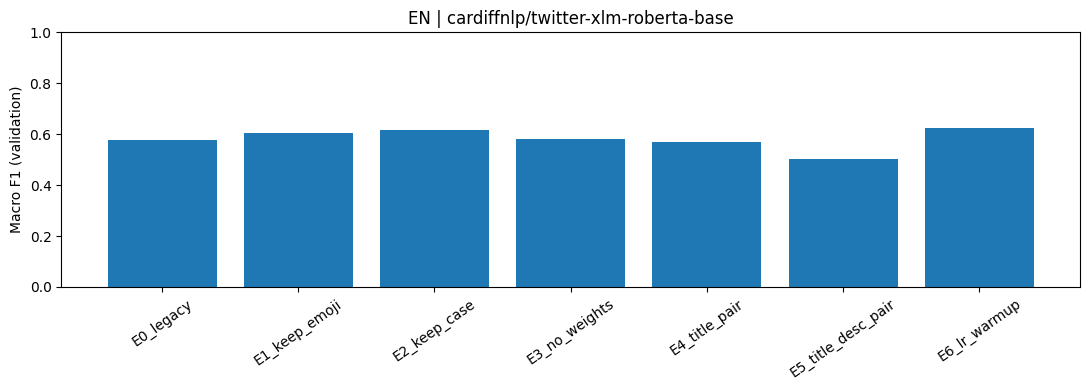

Merapikan checkpoint run kalah (artefak skor/riwayat/prediksi tetap disimpan).
en cardiffnlp/twitter-xlm-roberta-base -> checkpoint disimpan: E6_lr_warmup


In [ ]:
comparison=consolidate()
if comparison.empty:
    raise RuntimeError("Belum ada hasil validasi. Jalankan pelatihan pada sel 6 terlebih dahulu.")
cols=["language","model","run_name","macro_f1","accuracy","f1_no","f1_yes_implicit","f1_yes_explicit"]
display(comparison[cols].style.format({x:"{:.4f}" for x in cols if x not in ("language","model","run_name")}))

winners=(comparison.sort_values("macro_f1",ascending=False)
        .drop_duplicates(["language","model"]))
print("PEMENANG VALIDASI UNTUK SETIAP PASANG MODEL/BAHASA:")
display(winners[cols])
for (lang,model_name),group in comparison.groupby(["language","model"],sort=False):
    order=[x for x in RUN_NAMES if x in set(group["run_name"])]
    group=group.set_index("run_name").loc[order]
    fig,ax=plt.subplots(figsize=(11,4))
    ax.bar(group.index,group["macro_f1"])
    ax.set_ylim(0,1)
    ax.set(ylabel="Macro F1 (validation)",title=f"{lang.upper()} | {model_name}")
    ax.tick_params(axis="x",rotation=35)
    fig.tight_layout()
    out=OUT_DIR/lang/model_name.split("/")[-1]/"comparison_macro_f1.png"
    out.parent.mkdir(parents=True,exist_ok=True)
    fig.savefig(out,dpi=160)
    plt.show();plt.close(fig)

if KEEP_ONLY_WINNER_CHECKPOINT:
    print("Merapikan checkpoint run kalah (artefak skor/riwayat/prediksi tetap disimpan).")
    for (lang,model_name),group in comparison.groupby(["language","model"]):
        # Jangan hapus jika eksperimen belum lengkap: mungkin perlu dilanjutkan.
        if set(group["run_name"]) != set(RUN_NAMES):
            print("Belum lengkap, tidak menghapus checkpoint:",lang,model_name)
            continue
        best_name=group.sort_values("macro_f1",ascending=False).iloc[0]["run_name"]
        for other in group["run_name"]:
            if other != best_name:
                path=run_dir(lang,model_name,other)/"checkpoints"
                if path.exists(): shutil.rmtree(path)
        print(lang,model_name,"-> checkpoint disimpan:",best_name)

## 8. Evaluasi TEST internal — sengaja terpisah

**Jangan mengulang tes dan mengganti keputusan berdasarkan skor test.** Lihat tabel validasi lebih dahulu, putuskan model dan run final, barulah evaluasi sekali.

Untuk menjalankan: atur `RUN_FINAL_TEST=True` di sel konfigurasi, lalu **jalankan sel ini saja** (tidak perlu mengulang training) setelah seluruh eksperimen selesai. Sebagai kontrol akademik, pilih **satu** kombinasi model dan bahasa per evaluasi final. Script memakai `FINAL_LANGUAGE`, `FINAL_MODEL`, `FINAL_RUN` yang ditentukan dari skor validasi, bukan dari test.

In [ ]:
comparison=consolidate()
if not RUN_FINAL_TEST:
    print("Evaluasi test dikunci. Tinjau hasil validasi dahulu; ubah RUN_FINAL_TEST=True setelah final.")
else:
    assert not comparison.empty, "Hasil validasi belum tersedia"
    # Jika memilih lintas model, pastikan FINAL_MODEL dan FINAL_RUN ditetapkan berdasarkan validasi saja.
    FINAL_LANGUAGE=LANGUAGES[0]
    FINAL_MODEL=MODEL_NAMES[0]
    final_pool=comparison[(comparison["language"]==FINAL_LANGUAGE)&(comparison["model"]==FINAL_MODEL)]
    assert len(final_pool)==len(RUN_NAMES), "Selesaikan seluruh eksperimen sebelum tes."
    FINAL_RUN=final_pool.sort_values("macro_f1",ascending=False).iloc[0]["run_name"]
    print("Final (berdasarkan validasi):",FINAL_LANGUAGE,FINAL_MODEL,FINAL_RUN)
    destination=run_dir(FINAL_LANGUAGE,FINAL_MODEL,FINAL_RUN)
    target=destination/"test_metrics.json"
    if target.exists():
        print("Hasil test sudah ada, tidak dihitung ulang:")
        print(target.read_text(encoding="utf-8"))
    else:
        checkpoint=final_pool[final_pool["run_name"]==FINAL_RUN].iloc[0]["best_checkpoint"]
        assert Path(checkpoint).exists(),f"Checkpoint tidak ditemukan: {checkpoint}"
        tokenizer=AutoTokenizer.from_pretrained(FINAL_MODEL,use_fast=True)
        model=AutoModelForSequenceClassification.from_pretrained(checkpoint)
        conf=EXPERIMENTS[FINAL_RUN]
        test_ds=tokenize_split(DATA[FINAL_LANGUAGE]["test"],tokenizer,conf)
        args=TrainingArguments(output_dir=str(destination/"test_only"),
                               per_device_eval_batch_size=EVAL_BATCH_SIZE,report_to="none")
        trainer=WeightedTrainer(model=model,args=args,processing_class=tokenizer,
                    data_collator=DataCollatorWithPadding(tokenizer=tokenizer),compute_metrics=compute_metrics)
        pred=trainer.predict(test_ds)
        logits=pred.predictions[0] if isinstance(pred.predictions,tuple) else pred.predictions
        y_true=pred.label_ids; y_pred=np.asarray(logits).argmax(axis=-1)
        final_scores=prediction_scores(y_true,logits)
        save_json(target,{"language":FINAL_LANGUAGE,"model":FINAL_MODEL,"run_name":FINAL_RUN,
                          "scores":final_scores})
        pd.DataFrame(confusion_matrix(y_true,y_pred,labels=[0,1,2]),index=LABELS,columns=LABELS).to_csv(
            destination/"confusion_matrix_test.csv",index_label="actual_label")
        pd.DataFrame(classification_report(y_true,y_pred,labels=[0,1,2],target_names=LABELS,
            output_dict=True,zero_division=0)).transpose().to_csv(destination/"classification_report_test.csv")
        print("TEST INTERNAL (bukan official test SemEval):")
        display(pd.DataFrame([final_scores]))
        print(classification_report(y_true,y_pred,labels=[0,1,2],target_names=LABELS,zero_division=0))
        del trainer,model,test_ds,tokenizer
        gc.collect()
        if torch.cuda.is_available(): torch.cuda.empty_cache()

Evaluasi test dikunci. Tinjau hasil validasi dahulu; ubah RUN_FINAL_TEST=True setelah final.


## 9. Ekspor hasil CSV untuk artikel

Unduh perbandingan validasi. ZIP berisi **metrik, riwayat, tabel prediksi, dan grafik** tanpa bobot model yang besar. Boleh menyertakan bobot model terbaik secara terpisah melalui Google Drive.

In [ ]:
comparison=consolidate()
if comparison.empty:
    print("Belum ada hasil eksperimen yang dapat diekspor.")
else:
    archive_base=OUT_DIR/"laporan_ablation_e0_e6"
    import zipfile
    with zipfile.ZipFile(str(archive_base)+".zip","w",compression=zipfile.ZIP_DEFLATED) as archive:
        for file in OUT_DIR.rglob("*"):
            if file.is_file() and "checkpoints" not in file.parts and file.name!="laporan_ablation_e0_e6.zip":
                archive.write(file,arcname=file.relative_to(OUT_DIR))
    print("CSV:",OUT_DIR/"SEMUA_HASIL_VALIDASI.csv")
    print("ZIP:",str(archive_base)+".zip")
    display(FileLink(str(archive_base)+".zip"))
    print("Catatan: kirim CSV hasil ke chat agar saya bedah perbedaan semua tujuh eksperimen.")

CSV: /content/ablation_results/SEMUA_HASIL_VALIDASI.csv
ZIP: /content/ablation_results/laporan_ablation_e0_e6.zip


/content/ablation_results/laporan_ablation_e0_e6.zip

Catatan: kirim CSV hasil ke chat agar saya bedah perbedaan semua tujuh eksperimen.


## Catatan pelaporan untuk artikel

- Bandingkan hasil validation untuk menguji hipotesis masing-masing. **Jangan memilih E0–E6 memakai test**.
- Jika E1 mengungguli E0: emoji mungkin penting. Jika E2 mengungguli E1: kapitalisasi mungkin penting. Jika E3 mengungguli E2: bobot kelas sebelumnya mungkin kurang optimal.
- E4/E5 mengevaluasi apakah judul/deskripsi membantu memahami ujaran implisit. E6 mengubah **dua faktor sekaligus** (LR dan warmup), jadi jangan menyimpulkan efek masing-masing secara terpisah.
- Tinjau `f1_yes_implicit`, tidak hanya Macro F1. Semakin tinggi F1 validation bukan jaminan perbaikan generalisasi test.
- Skor E0 yang dilatih ulang bisa berbeda dari notebook lama karena perubahan versi library, seed, kondisi eksekusi, atau implementasi determinisme. Untuk publikasi, replikasi kandidat terbaik dengan beberapa seed dan laporkan rerata ± simpangan baku.
- **Test internal** adalah split internal dataset yang diunggah, bukan test resmi kompetisi SemEval 2027.